# VLM Prompt Engineering — Caption / OCR / Reasoning / Structured Output

Qwen3-VL(Ollama)을 호출하며 프롬프트 작성 방식에 따라 결과가 어떻게
달라지는지 직접 비교합니다.

## 사전 준비
```bash
uv sync
ollama pull qwen3-vl:4b-instruct
```

In [1]:
from vlm_utils import ask, ask_json, show

PRODUCT = "data/product.png"
RECEIPT = "data/receipt.png"
BAR_CHART = "data/bar_chart.png"

## Caption Prompt
같은 이미지라도 "범위 / 관점 / 용도"를 지정하지 않으면 VLM은 스스로
분량과 톤을 정해버립니다. 나쁜 예 / 좋은 예를 나란히 비교해봅니다.

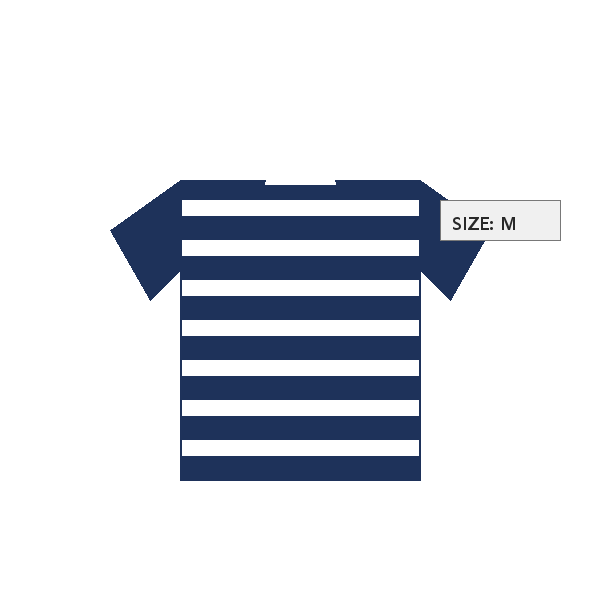

In [2]:
show(PRODUCT)

In [3]:
bad = ask(PRODUCT, "이 이미지를 설명해줘.")
print("[나쁜 예]\n", bad)

[나쁜 예]
 이 이미지는 **네이비 블루와 하얀색으로 된 가로 줄무늬 티셔츠**의 일러스트레이션입니다.  

- **디자인**: 단순한 평면 스타일로, 티셔츠의 허리와 어깨 부분은 네이비 블루로, 가로로 이어지는 **7개의 하얀색 줄무늬**가 블루 바탕 위에 정확히 배치되어 있습니다.  
- **사이즈 정보**: 우측 상단에는 **"SIZE: M"**라고 적힌 작은 흰색 라벨이 붙어 있으며, 이는 "M"(메디움) 사이즈를 나타냅니다.  
- **배경**: 전체적으로 흰색 배경으로, 티셔츠 그림이 돋보이게 표현되어 있습니다.  

이미지는 의류 상품을 설명하는 데 사용되는 유형의 아이콘으로, 디테일이 적절히 간결하게 처리되어 있습니다.


In [4]:
good = ask(
    PRODUCT,
    "이 상품 이미지를 온라인 쇼핑몰 상세페이지용 alt 텍스트로 쓸 수 있게, "
    "색상·소재·형태를 포함해 한국어 한 문장으로 설명해줘.",
)
print("[좋은 예]\n", good)

[좋은 예]
 이 제품은 나이플리 블루와 흰색의 가로 줄무늬 코튼 소재 단순한 티셔츠로, 사이즈 M입니다.


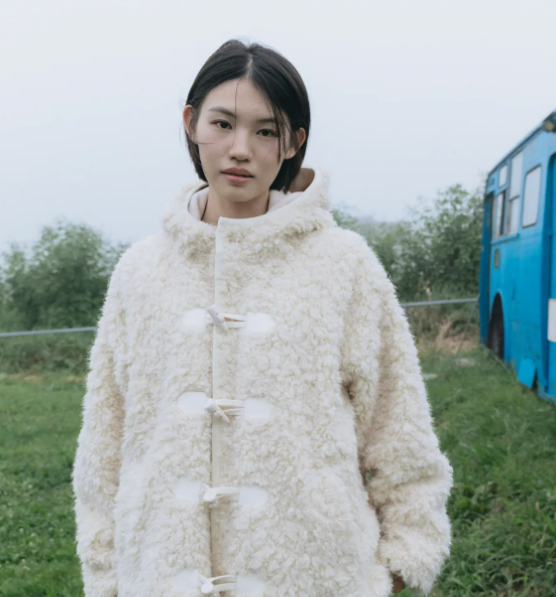

In [5]:
PRODUCT01 = "./data/product01.png"
show(PRODUCT01)

In [ ]:
bad = ask(PRODUCT01, "이 이미지를 설명해줘.")

# 상품 뿐만 아니라, 주변의 차량과 풍경도 같이 설명하고 있음
print("[나쁜 예]\n", bad)

[나쁜 예]
 이 이미지는 흐린 하늘 아래 초록색 잔디밭 위에 서 있는 사람을 보여줍니다.  
**주인공**은 부드러운 흰색 풀绒 재질의 **코트**를 입고 있으며, 코트는 큰 머리罩(hood)와 둥근 토글 버튼(화이트)이 특징입니다. 짧은 검은 머리카락을 가지고 있으며, 심플한 표정을 하고 있습니다.  

**배경**에는 오른쪽으로 **남색 버스**가 선명하게 보이며, 버스 주변에는 나무와 풀이 자라 있고, 흐린 하늘과 푸른 자연경관이 조화롭게 어우러져 **평화롭고 차분한 분위기**를 연출합니다.  
전체적으로 **겨울철이나 춥는 날씨**를 연상시키는 스타일로, 자연과 인류 문화 요소(버스)가 조화로운 상징적 이미지로 느껴집니다.


In [ ]:
good = ask(
    PRODUCT01,
    "이 상품 이미지를 온라인 쇼핑몰 상세페이지용 alt 텍스트로 쓸 수 있게, "
    "성별·색상·소재·형태를 포함해 한국어 한 문장으로 설명해줘.",
)

# 주변에 대한 설명이 아닌 오직 상품에 대한 답변만 생성함 
print("[좋은 예]\n", good)

[좋은 예]
 여성용 크림색 플러스 소재 후드 코트로, 부드러운 털감과 대형 버튼이 특징인 긴 형태의 겨울 코트입니다.


## OCR Prompt
"읽어줘" 대신 **"그대로 전사(transcribe)해줘"**라고 요청하면 임의 요약/의역이
줄어듭니다.

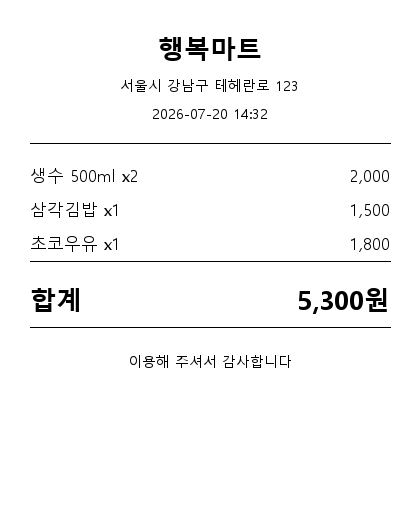

In [2]:
show(RECEIPT)

In [9]:
bad_ocr = ask(RECEIPT, "이 이미지에 뭐라고 써있어?")
print("[나쁜 예]\n", bad_ocr)

[나쁜 예]
 이 이미지는 행복마트(행복마트)의 구매내역을 보여주는 문서로, 다음 내용이 쓰여 있습니다:

- **영업소 정보**: 서울시 강남구 테헤란로 123  
- **날짜 및 시간**: 2026-07-20 14:32  
- **구매 상품**:  
  - 생수 500ml x2 → 2,000원  
  - 삼각김밥 x1 → 1,500원  
  - 초코우유 x1 → 1,800원  
- **합계**: 5,300원  
- **마무리 문구**: 이용해 주셔서 감사합니다  

이 문서는 일반적인 가격표나 결제 내역을 보여주는 형식으로, 특정 상품과 금액, 그리고 총합을 명시하고 있습니다.


In [3]:
good_ocr = ask(
    RECEIPT,
    "읽을 수 없는 글자는 [?]로 표시하고, 임의로 고치거나 요약하지 마."
    "영수증 이미지에서 상호명, 거래일시, 총액, 결제수단, 구매 품목(상품명·수량·금액)을 추출해줘. 확인할 수 없는 값은 null로 표시하고, 추측하지 마.",
)
print("[좋은 예]\n", good_ocr)

[좋은 예]
 {
  "상호명": "행복마트",
  "거래일시": "2026-07-20 14:32",
  "총액": "5,300원",
  "결제수단": null,
  "구매 품목": [
    {
      "상품명": "생수 500ml",
      "수량": "x2",
      "금액": "2,000"
    },
    {
      "상품명": "삼각김밥",
      "수량": "x1",
      "금액": "1,500"
    },
    {
      "상품명": "초코우유",
      "수량": "x1",
      "금액": "1,800"
    }
  ]
}


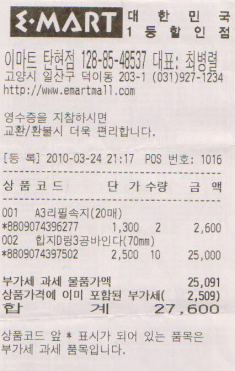

In [5]:
RECEIPT01 = "./data/receipt01.png"
show(RECEIPT01)

In [12]:
bad_ocr = ask(RECEIPT01, "이 이미지에 뭐라고 써있어?")
print("[나쁜 예]\n", bad_ocr)

[나쁜 예]
 이 이미지는 엑스마트(EMART)의 영수증입니다. 아래와 같이 쓰여 있습니다:

---

### **상단 정보**  
- **로고 및 상호**: `E·MART` (대한민국 1등할인점)  
- **매장 정보**:  
  - 이마트 탄현점  
  - 전화번호: 128-85-48537  
  - 주소: 고양시 일산구 덕이동 203-1  
  - 연락처: (031)927-1234  
  - 웹사이트: http://www.emartmall.com  

---

### **공지사항**  
- "영수증을 지참하시면 교환/환불시 더욱 편리합니다."  

---

### **거래 정보**  
- **등록 시간**: 2010-03-24 21:17  
- **POS 번호**: 1016  

---

### **구매 상품 목록**  
1. **001** A3리필속지(20매)  
   - 번호: *8809074396277  
   - 단가: 1,300  
   - 수량: 2  
   - 금액: 2,600  

2. **002** 허지D링3공바인다(70mm)  
   - 번호: *8809074397502  
   - 단가: 2,500  
   - 수량: 10  
   - 금액: 25,000  

---

### **합계 정보**  
- **부가세 과세 물품가액**: 25,091  
- **상품가격에 이미 포함된 부가세**: 2,509  
- **총 금액**: 27,600  

---

### **기타 설명**  
- "상품코드 앞 * 표시가 되어 있는 품목은 부가세 과세 품목입니다."  

--- 

이 영수증은 2010년 3월 24일 21시 17분에 작성된 엑스마트 탄현점에서의 구매 내역을 기록한 문서입니다.


In [6]:
good_ocr = ask(
    RECEIPT01,
    "읽을 수 없는 글자는 [?]로 표시하고, 임의로 고치거나 요약하지 마."
    "영수증 이미지에서 상호명, 거래일시, 총액, 결제수단, 구매 품목(상품명·수량·금액)을 추출해줘. 확인할 수 없는 값은 null로 표시하고, 추측하지 마.",
)
print("[좋은 예]\n", good_ocr)

[좋은 예]
 {
  "상호명": "이마트 탄협점",
  "거래일시": "2010-03-24 21:17",
  "총액": "27,600",
  "결제수단": "카드",
  "구매 품목": [
    {
      "상품명": "A3리필속지(20매)",
      "수량": "2",
      "금액": "2,600"
    },
    {
      "상품명": "흰지D링3공바인다(70mm)",
      "수량": "10",
      "금액": "25,000"
    }
  ]
}


## Reasoning Prompt
단순 인식이 아니라 **근거를 먼저 설명한 뒤 답을 제시**하도록 요청하면
할루시네이션이 줄어듭니다. "모르면 모른다"고 답하게 만드는 것도 중요합니다.

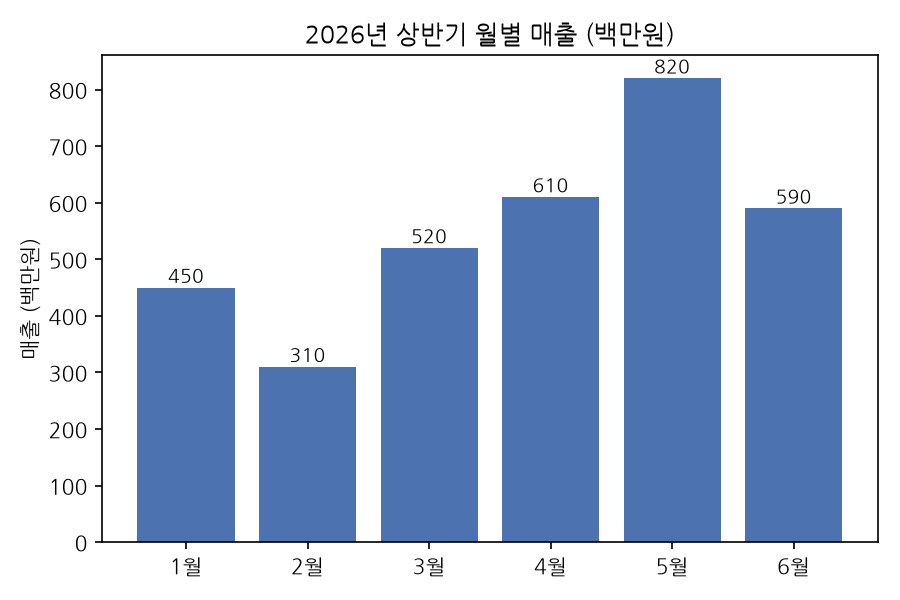

In [15]:
show(BAR_CHART)

In [ ]:
reasoning = ask(
    BAR_CHART,
    "이 막대그래프에서 값이 가장 큰 달과 가장 작은 달의 차이를 계산해줘. "
    "판단 근거(그래프의 어느 막대를 비교했는지)를 먼저 설명한 뒤 답을 제시하고, "
    "그래프에 없는 값은 추정하지 말고 '확인 불가'라고 답해.",
)

print(reasoning)

**판단 근거**:  
이 막대그래프에서 "2026년 상반기 월별 매출 (백만원)"을 나타내며, 1월부터 6월까지의 매출 데이터가 직접 표시되어 있습니다.  
- **가장 큰 달**: 5월(5월)의 막대(820 백만원)  
- **가장 작은 달**: 2월(2월)의 막대(310 백만원)  

**계산**: 820 - 310 = **510** (백만원)  

**답변**: 510


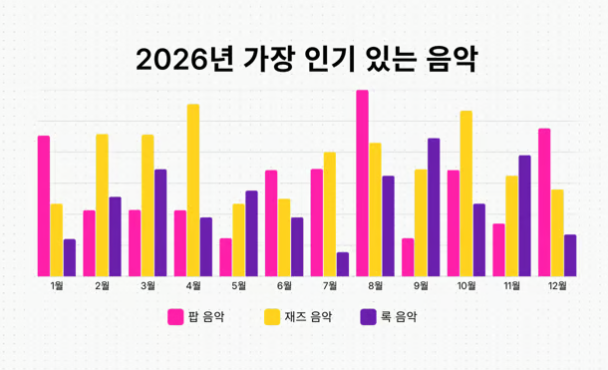

In [7]:
BAR_CHART01 = "./data/bar_chart01.png"
show(BAR_CHART01)

In [8]:
reasoning = ask(
    BAR_CHART01,
    "월별 가장 인기 있는 음악 종류를 설명해줘."
    "월별 가장 인기 있는 음악 종류를 바탕으로 겨울에 듣기 좋은 음악 종류 추천해줘.",
)
print(reasoning)

이 그래프는 **2026년 가장 인기 있는 음악 종류**를 월별로 나타낸 것입니다. 색상에 따라 음악 장르를 구분했으며:

- **핑크 (팝 음악)**: 전체적으로 가장 높은 인기. 특히 8월과 12월에 가장 높은 인기.
- **노란색 (재즈 음악)**: 4월, 10월에 인기 있는 것으로 보이며, 전체적으로 중간 수준의 인기.
- **보라색 (록 음악)**: 9월에 가장 높은 인기. 1월, 2월, 11월에 비교적 낮은 인기.

---

## 📅 **월별 가장 인기 있는 음악 종류**

| 월 | 가장 인기 있는 음악 종류 | 주요 흐름 |
|----|--------------------------|----------|
| **1월** | **팝** | 겨울 시즌의 시작. 감성적인 톤으로 인기 |
| **2월** | **재즈** | 겨울에 흐르는 따뜻하고 감성적인 음악 |
| **3월** | **록** | 봄을 맞이하는 에너지 넘치는 음악 |
| **4월** | **재즈** | 봄철에 흐르는 고요한 감성 |
| **5월** | **팝** | 봄의 시작과 함께 감성적이고 젊은 감각 |
| **6월** | **팝** | 여름에 맞는 감성과 흐르는 에너지 |
| **7월** | **팝** | 여름철의 고조기. 인기가 높은 계절 |
| **8월** | **팝** (가장 높은 인기) | 여름 최고의 음악! 여름을 맞이하는 최고의 장르 |
| **9월** | **록** (가장 높은 인기) | 가을의 시작, 열정과 에너지 넘치는 음악 |
| **10월** | **재즈** | 가을에 맞는 감성과 따뜻함 |
| **11월** | **팝** | 겨울의 시작, 감성적인 감각 |
| **12월** | **팝** | 겨울철의 감성적이고 감성적인 음악 |

---

## 🎧 **겨울에 듣기 좋은 음악 종류 추천**

겨울철(11월~1월)에는 **팝 음악**이 가장 인기 있고, **감성적이고 따뜻한 음악**으로 더 잘 어울립니다.

### ✅ 추천 음악 장르: **팝 음악**

- **감

## Structured Output
후속 처리가 가능하도록 **JSON 스키마를 예시와 함께 명시**하고,
`ollama`의 `format="json"` 옵션(`ask_json`)으로 파싱 가능한 응답을 강제합니다.

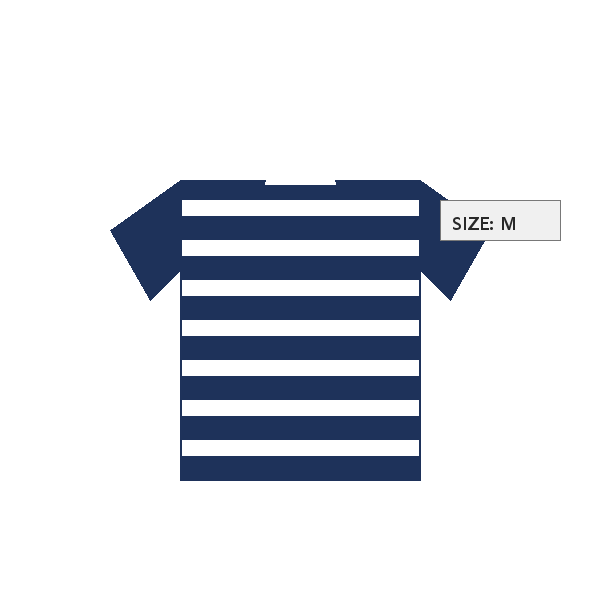

In [9]:
show(PRODUCT)

In [22]:
schema_prompt = '''
아래 JSON 스키마에 맞춰서만 답해. 다른 설명 문장은 출력하지 마.
{
  "category": "string",
  "color": "string",
  "pattern": "string",
  "size": "string"
}
'''
result = ask_json(PRODUCT, schema_prompt)
print(type(result), result)
assert set(result.keys()) >= {"category", "color", "pattern", "size"}

<class 'dict'> {'category': 'T-shirt', 'color': 'navy blue', 'pattern': 'horizontal stripes', 'size': 'M'}


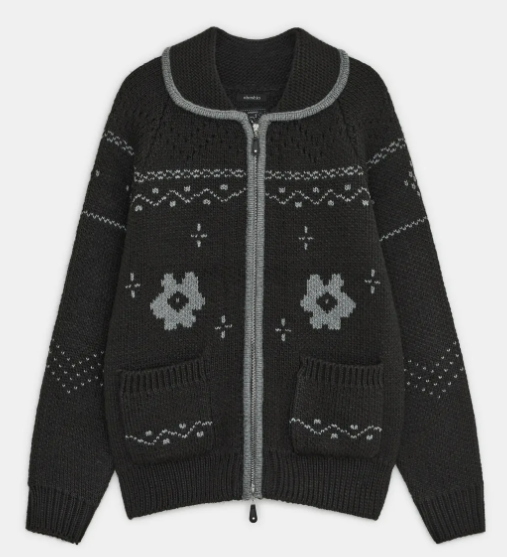

In [10]:
PRODUCT02 = "./data/product02.png"
show(PRODUCT02)

In [12]:
schema_prompt = '''
아래 JSON 스키마에 맞춰서만 답해. 다른 설명 문장은 출력하지 마.(없으면, None)
{
  "category": "string",
  "color": "string",
  "pattern": "string",
  "size": "string"
}
'''
result = ask_json(PRODUCT02, schema_prompt)
print(type(result), result)
assert set(result.keys()) >= {"category", "color", "pattern", "size"}

<class 'dict'> {'category': 'coat', 'color': 'black', 'pattern': 'snowflake', 'size': 'None'}
